In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron    # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential     # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense     #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D     # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models
     

In [3]:
df = pd.read_csv("C:/Users/HP/OneDrive/CNN/mnist_train.csv")
df_test = pd.read_csv("C:/Users/HP/OneDrive/CNN/mnist_test.csv")

In [5]:
df.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
df.shape

(60000, 785)

In [6]:
df.columns

Index(['label', '1x1', '1x2', '1x3', '1x4', '1x5', '1x6', '1x7', '1x8', '1x9',
       ...
       '28x19', '28x20', '28x21', '28x22', '28x23', '28x24', '28x25', '28x26',
       '28x27', '28x28'],
      dtype='str', length=785)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, label to 28x28
dtypes: int64(785)
memory usage: 359.3 MB


In [8]:
df.isnull().sum()

label    0
1x1      0
1x2      0
1x3      0
1x4      0
        ..
28x24    0
28x25    0
28x26    0
28x27    0
28x28    0
Length: 785, dtype: int64

In [10]:
# Preprocess
X_train=df.drop('label', axis=1).values
y_train=df['label'].values
X_test=df_test.drop('label',axis=1).values
y_test=df_test['label'].values

In [11]:
X_train=X_train.astype('float32')/255.0
X_test=X_test.astype('float32')/255.0

In [14]:
X_train_img=X_train.reshape(-1,28,28)
X_test_img=X_test.reshape(-1,28,28)

In [16]:
X_train_img

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [17]:
y_train_cat=to_categorical(y_train,10)
y_test_cat=to_categorical(y_test,10)

In [18]:
# Creating perceptron model
Perceptron=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10, activation='softmax')
])

In [19]:
Perceptron.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

In [20]:
history_percp=Perceptron.fit(X_train_img,y_train_cat, epochs=5, 
                             batch_size=32, validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.8188 - loss: 0.7702 - val_accuracy: 0.8830 - val_loss: 0.4808
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8809 - loss: 0.4566 - val_accuracy: 0.8952 - val_loss: 0.3996
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.8911 - loss: 0.4034 - val_accuracy: 0.9017 - val_loss: 0.3664
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8969 - loss: 0.3769 - val_accuracy: 0.9065 - val_loss: 0.3479
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9007 - loss: 0.3602 - val_accuracy: 0.9089 - val_loss: 0.3361


In [23]:
acc_percp=Perceptron.evaluate(X_test_img,y_test_cat,verbose=0)[1]

In [24]:
acc_percp

0.9089000225067139

In [26]:
# ANN
ann=Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [27]:
ann.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [28]:
history_ann=ann.fit(X_train_img, y_train_cat, epochs=5, batch_size=32, 
                validation_data=(X_test_img, y_test_cat), verbose=1)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.9322 - loss: 0.2327 - val_accuracy: 0.9624 - val_loss: 0.1197
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9705 - loss: 0.0994 - val_accuracy: 0.9675 - val_loss: 0.0960
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 11ms/step - accuracy: 0.9783 - loss: 0.0694 - val_accuracy: 0.9744 - val_loss: 0.0804
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 11ms/step - accuracy: 0.9833 - loss: 0.0542 - val_accuracy: 0.9728 - val_loss: 0.0867
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.9858 - loss: 0.0429 - val_accuracy: 0.9772 - val_loss: 0.0770


In [29]:
acc_ann=ann.evaluate(X_test_img, y_test_cat, verbose=0)[1]

In [30]:
acc_ann

0.9771999716758728

 before the training cnn we need to change the shape before we created'

 1 is a number of layers-- because we use here grey scale image( 1, is represent the number of color channels)

 if we use rgb (red, yellow, blue) colored we need to chage it as 3 insted of 1

In [70]:
X_train_cnn=X_train.reshape(-1,28,28,1)
X_test_cnn=X_test.reshape(-1,28,28,1)  # 1 is a number of layers it is also called as channel

In [71]:
#CNN
cnn=Sequential([
    Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=(28,28,1)), #28*28 are pixcel and 1 is channel
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64, kernel_size=(3,3), activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5), 
    Dense(10, activation='softmax')
])

In [72]:
cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


In [73]:
history_cnn=cnn.fit(X_train_img, y_train_cat, epochs=5, batch_size=32, 
                    validation_data=(X_test_img, y_test_cat), verbose=1)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 66s 33ms/step - accuracy: 0.9382 - loss: 0.2001 - val_accuracy: 0.9868 - val_loss: 0.0415
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 63s 34ms/step - accuracy: 0.9787 - loss: 0.0737 - val_accuracy: 0.9904 - val_loss: 0.0303
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 40s 21ms/step - accuracy: 0.9840 - loss: 0.0530 - val_accuracy: 0.9905 - val_loss: 0.0288
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 51s 27ms/step - accuracy: 0.9872 - loss: 0.0435 - val_accuracy: 0.9919 - val_loss: 0.0276
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 73s 23ms/step - accuracy: 0.9890 - loss: 0.0363 - val_accuracy: 0.9901 - val_loss: 0.0288


In [74]:
acc_cnn=cnn.evaluate(X_test_img, y_test_cat, verbose=0)[1]

In [75]:
acc_cnn

0.9901000261306763

In [76]:
def plot_training(history, title):
    plt.figure(figsize=(12, 4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Trian Accuracy")
    plt.plot(history.history['val_accuracy'], label='val accuracy')
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train loss")
    plt.plot(history.history['val_loss'], label='val loss')
    plt.title(f"{title} loss")
    plt.legend()
    plt.show()

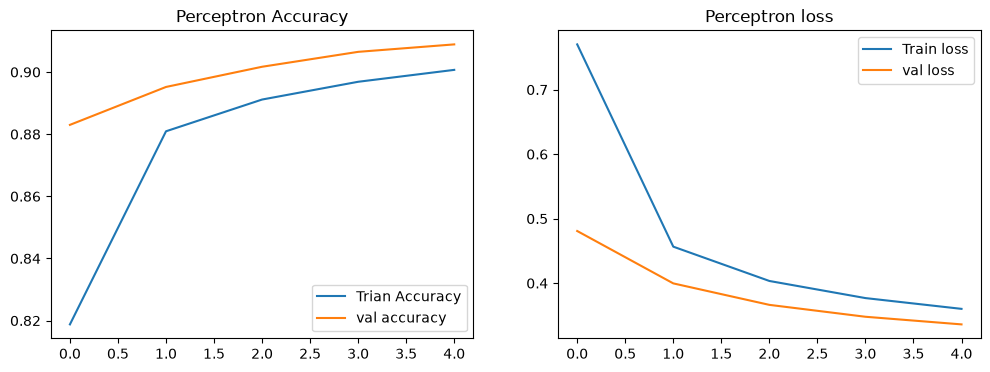

In [77]:
plot_training(history_percp, 'Perceptron')

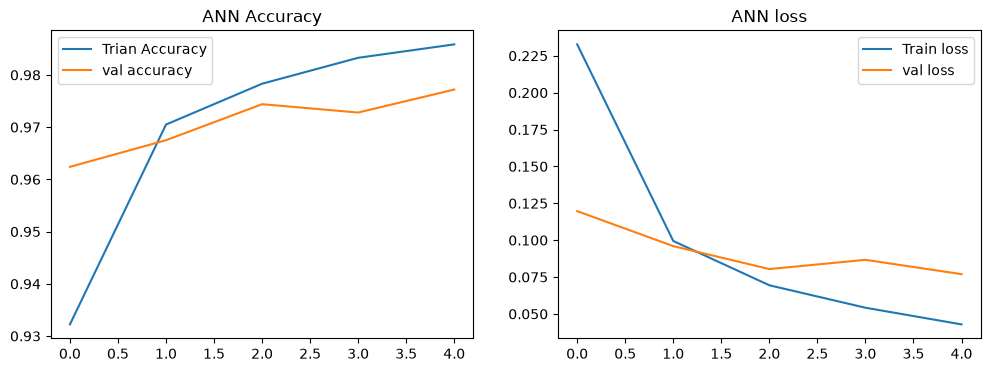

In [78]:
plot_training(history_ann, 'ANN')

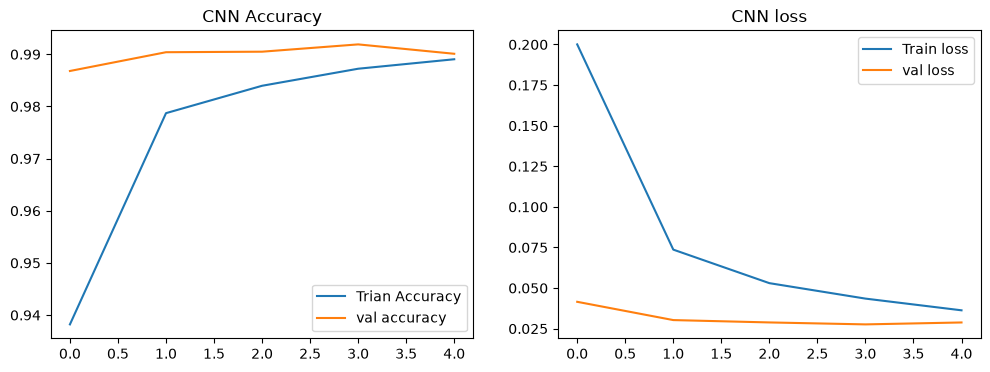

In [79]:
plot_training(history_cnn, 'CNN')

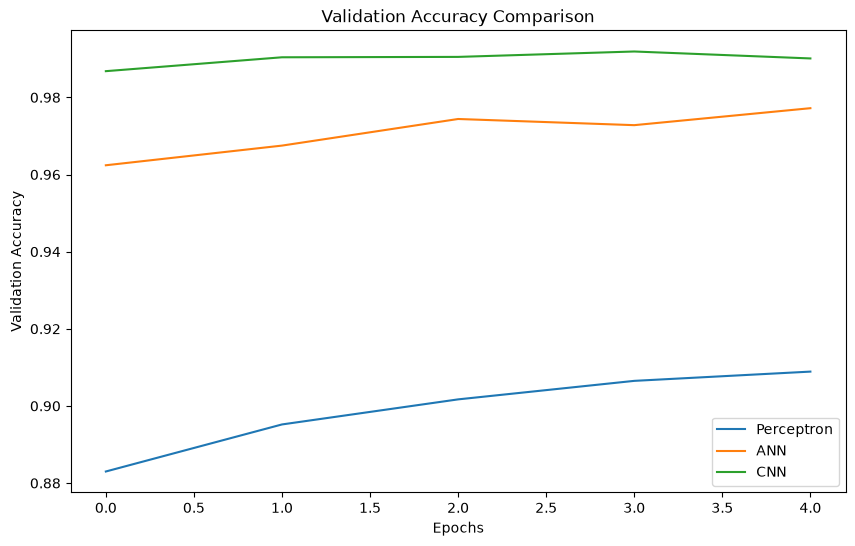

In [80]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history['val_accuracy'], label='Perceptron')
plt.plot(history_ann.history['val_accuracy'], label='ANN')
plt.plot(history_cnn.history['val_accuracy'], label='CNN')  
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')       
plt.legend()
plt.show()

In [81]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()
     

ValueError: Exception encountered when calling Sequential.call().

[1mCannot take the length of shape with unknown rank.[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=<unknown>, dtype=float32)
  • training=False
  • mask=None
  • kwargs=<class 'inspect._empty'>

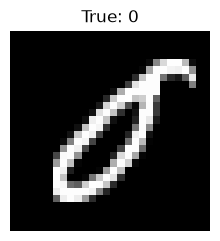

In [82]:
show_side_by_side([Perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], X_test_img, X_test_cnn, y_test, 5)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


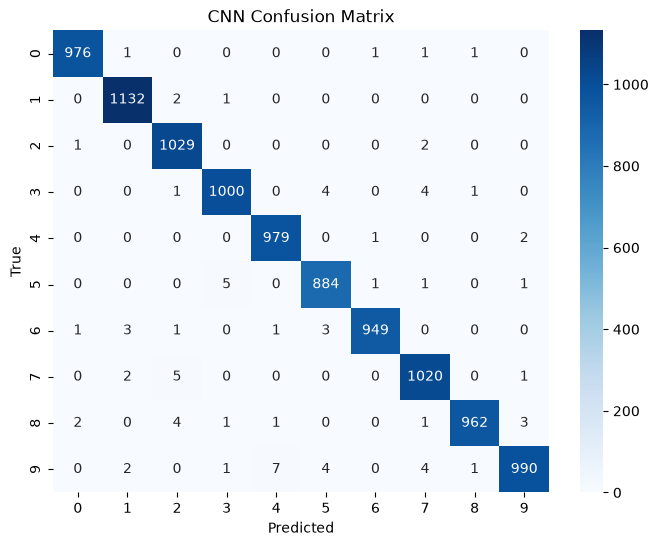

In [65]:
y_pred_cnn = np.argmax(cnn.predict(X_test_img), axis=1)
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

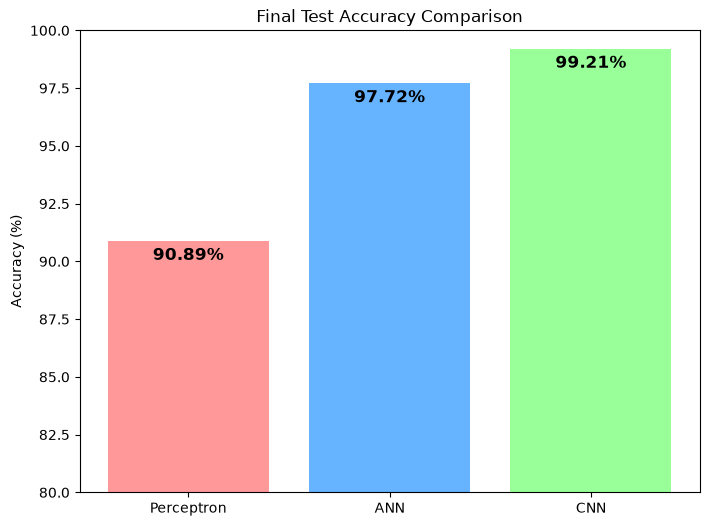

In [66]:
final_accs = [acc_percp*100, acc_ann*100, acc_cnn*100]
models = ["Perceptron", "ANN", "CNN"]

plt.figure(figsize=(8,6))
bars = plt.bar(models, final_accs, color=['#ff9999','#66b3ff','#99ff99'])
plt.title("Final Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
for bar, acc in zip(bars, final_accs):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()-1, f"{acc:.2f}%",
             ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.ylim(80, 100)
plt.show()